Milestone 1

In [1]:
# Install dependencies if needed:
# pip install statsmodels scipy pandas matplotlib
import numpy as np
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from scipy.stats import fisher_exact

# Audit data (taken from the problem statement)
n_total, k_total = 400, 60   # all audited crowd tickets, total disagreements
n_A, k_A = 180, 12           # Tier A: audited, disagreements
n_B, k_B = 220, 48           # Tier B: audited, disagreements

# 1) Noise rate with 95% confidence intervals (Wald and Wilson)
for name, k, n in [("Overall", k_total, n_total), ("Tier A", k_A, n_A), ("Tier B", k_B, n_B)]:
    p = k / n
    wald = proportion_confint(k, n, alpha=0.05, method="normal")
    wilson = proportion_confint(k, n, alpha=0.05, method="wilson")
    print(f"{name}: p={p:.4f} | Wald=[{wald[0]:.4f}, {wald[1]:.4f}] | Wilson=[{wilson[0]:.4f}, {wilson[1]:.4f}]")

# 2) Tier A vs Tier B: two-proportion z-test (pooled variance under H0)
z, pval = proportions_ztest([k_B, k_A], [n_B, n_A], alternative="two-sided")
print(f"\nz = {z:.3f}, p-value = {pval:.2e}")

# 95% CI for the difference in proportions (unpooled standard error)
pA, pB = k_A / n_A, k_B / n_B
diff = pB - pA
se = np.sqrt(pA * (1 - pA) / n_A + pB * (1 - pB) / n_B)
print(f"Diff (B - A) = {diff:.4f}, 95% CI = [{diff - 1.96 * se:.4f}, {diff + 1.96 * se:.4f}]")

# Fisher's exact test as a cross-check (better for small counts)
odds, p_fisher = fisher_exact([[k_B, n_B - k_B], [k_A, n_A - k_A]])
print(f"Fisher exact p = {p_fisher:.2e}, odds ratio = {odds:.2f}")

# 3) Noise rate for the full 50K dataset
# Assumption: the 5,000 expert-labeled tickets are clean, so only the
# 45,000 crowd tickets (90% of the data) contribute noise.
crowd_lo, crowd_hi = proportion_confint(k_total, n_total, alpha=0.05, method="wilson")
print(f"\nCrowd portion (45K): {k_total / n_total:.1%}")
print(f"Full 50K dataset: {0.9 * k_total / n_total:.1%} "
      f"(95% CI: {0.9 * crowd_lo:.1%} - {0.9 * crowd_hi:.1%})")

Overall: p=0.1500 | Wald=[0.1150, 0.1850] | Wilson=[0.1183, 0.1883]
Tier A: p=0.0667 | Wald=[0.0302, 0.1031] | Wilson=[0.0385, 0.1129]
Tier B: p=0.2182 | Wald=[0.1636, 0.2728] | Wilson=[0.1687, 0.2773]

z = 4.222, p-value = 2.42e-05
Diff (B - A) = 0.1515, 95% CI = [0.0859, 0.2171]
Fisher exact p = 1.83e-05, odds ratio = 3.91

Crowd portion (45K): 15.0%
Full 50K dataset: 13.5% (95% CI: 10.7% - 16.9%)


Milestone 2

                Billing  Refund  Technical  Account Access  Shipping  Other
Billing               0      14          0               0         0      3
Refund               12       0          0               0         0      0
Technical             0       0          0               9         0      5
Account Access        0       0          6               0         0      0
Shipping              0       0          0               0         0      8
Other                 0       0          0               0         3      0 



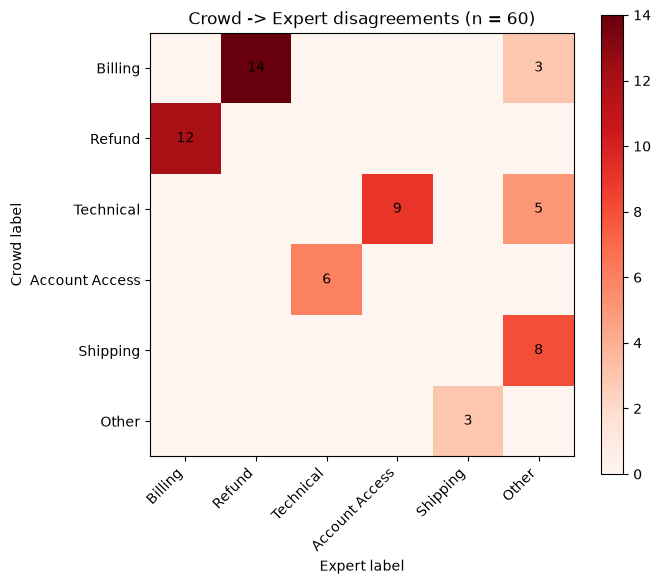

       class_1   class_2  count  share_of_errors  cumulative_share
       Billing    Refund     26         0.433333          0.433333
Account Access Technical     15         0.250000          0.683333
         Other  Shipping     11         0.183333          0.866667
         Other Technical      5         0.083333          0.950000
       Billing     Other      3         0.050000          1.000000

Non-zero off-diagonal cells: 8 of 30 possible


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Disagreement counts (crowd label -> expert label), from the problem statement
rows = [
    ("Billing", "Refund", 14),
    ("Refund", "Billing", 12),
    ("Technical", "Account Access", 9),
    ("Shipping", "Other", 8),
    ("Account Access", "Technical", 6),
    ("Technical", "Other", 5),
    ("Other", "Shipping", 3),
    ("Billing", "Other", 3),
]
df = pd.DataFrame(rows, columns=["crowd", "expert", "count"])
assert df["count"].sum() == 60  # sanity check against the audit total

classes = ["Billing", "Refund", "Technical", "Account Access", "Shipping", "Other"]

# 1) Confusion-style matrix of disagreements (rows = crowd, cols = expert)
mat = pd.DataFrame(0, index=classes, columns=classes)
for _, r in df.iterrows():
    mat.loc[r["crowd"], r["expert"]] = r["count"]
print(mat, "\n")

# 2) Heatmap
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(mat.values, cmap="Reds")
ax.set_xticks(range(6)); ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(6)); ax.set_yticklabels(classes)
ax.set_xlabel("Expert label"); ax.set_ylabel("Crowd label")
ax.set_title("Crowd -> Expert disagreements (n = 60)")
for i in range(6):
    for j in range(6):
        if mat.values[i, j] > 0:
            ax.text(j, i, mat.values[i, j], ha="center", va="center")
plt.colorbar(im)
plt.tight_layout()
plt.show()

# 3) Pair-level view: merge both directions of each confusable pair
pairs = {}
for _, r in df.iterrows():
    key = tuple(sorted([r["crowd"], r["expert"]]))
    pairs[key] = pairs.get(key, 0) + r["count"]
pair_df = (pd.DataFrame([(a, b, c) for (a, b), c in pairs.items()],
                        columns=["class_1", "class_2", "count"])
           .sort_values("count", ascending=False))
pair_df["share_of_errors"] = pair_df["count"] / 60
pair_df["cumulative_share"] = pair_df["share_of_errors"].cumsum()
print(pair_df.to_string(index=False))

# 4) Concentration: only 8 of 30 possible off-diagonal cells are non-zero
n_nonzero = (mat.values > 0).sum()
print(f"\nNon-zero off-diagonal cells: {n_nonzero} of 30 possible")

testing if noise is random or not 

In [3]:
import numpy as np

rng = np.random.default_rng(42)

# Observed disagreement counts: 8 non-zero cells, 22 empty cells (30 off-diagonal total)
observed = np.array([14, 12, 9, 8, 6, 5, 3, 3] + [0] * 22)
N, n_cells = observed.sum(), len(observed)   # 60 errors, 30 cells
expected = N / n_cells                       # 2.0 per cell under H0

# Chi-square statistic: sum((O - E)^2 / E)
def chi2_stat(counts):
    return ((counts - expected) ** 2 / expected).sum()

obs_chi2 = chi2_stat(observed)

# Monte Carlo: drop 60 errors uniformly across 30 cells, 10,000 times
n_sims = 10_000
sim_counts = rng.multinomial(N, [1 / n_cells] * n_cells, size=n_sims)
sim_chi2 = np.array([chi2_stat(c) for c in sim_counts])
sim_nonzero = (sim_counts > 0).sum(axis=1)

# p-value: how often does uniform noise look at least as concentrated as ours?
p_mc = (np.sum(sim_chi2 >= obs_chi2) + 1) / (n_sims + 1)

print(f"Observed chi2 = {obs_chi2:.1f}")
print(f"Simulated chi2: mean = {sim_chi2.mean():.1f}, max = {sim_chi2.max():.1f}")
print(f"Monte Carlo p-value = {p_mc:.4f}  (floor is 1/{n_sims + 1})")
print(f"Non-zero cells: observed = {(observed > 0).sum()}, "
      f"uniform-noise average = {sim_nonzero.mean():.1f}")

Observed chi2 = 222.0
Simulated chi2: mean = 29.0, max = 64.0
Monte Carlo p-value = 0.0001  (floor is 1/10001)
Non-zero cells: observed = 8, uniform-noise average = 26.1


In [4]:
import numpy as np

obs_acc = 0.82   # accuracy measured on the noisy test set
eta = 0.15       # assumed uniform label-flip rate
K = 6            # number of classes

# Solve obs = a*(1-eta) + (1-a)*eta/(K-1) for the true accuracy a
true_acc = (obs_acc - eta / (K - 1)) / (1 - eta - eta / (K - 1))
print(f"Estimated true accuracy = {true_acc:.4f}")           # ~0.9634
print(f"Naive (obs / (1-eta))   = {obs_acc / (1 - eta):.4f}")  # ~0.9647

# Sensitivity: how does the estimate move if the noise rate itself is uncertain?
# eta bounds come from the M1 Wilson CI [0.118, 0.188]; the full-dataset value is 13.5%
for e in [0.118, 0.135, 0.15, 0.188]:
    a = (obs_acc - e / (K - 1)) / (1 - e - e / (K - 1))
    print(f"eta = {e:.3f} -> true accuracy = {a:.4f}")

Estimated true accuracy = 0.9634
Naive (obs / (1-eta))   = 0.9647
eta = 0.118 -> true accuracy = 0.9278
eta = 0.135 -> true accuracy = 0.9463
eta = 0.150 -> true accuracy = 0.9634
eta = 0.188 -> true accuracy = 1.0103


Milestone 4 

In [ ]:

#  Ticket-selection simulation (leakage-free)
#
# NOTE: Model confidence is ASSUMED (Beta distributions), not measured on real data.
# Results illustrate strategy behavior only; they are not performance on HelpDeskNet-50K.

import numpy as np
from scipy.stats import beta as beta_dist

rng = np.random.default_rng(0)

classes = ["Billing", "Refund", "Technical", "Account Access", "Shipping", "Other"]
share = np.array([0.30, 0.15, 0.25, 0.15, 0.10, 0.05])
idx = {c: i for i, c in enumerate(classes)}
N, K = 45_000, 2000   # crowd-labeled tickets, expert review budget

# Audit pairs (crowd label, true/expert label, count) from the problem statement
pairs = [("Billing", "Refund", 14), ("Refund", "Billing", 12),
         ("Technical", "Account Access", 9), ("Shipping", "Other", 8),
         ("Account Access", "Technical", 6), ("Technical", "Other", 5),
         ("Other", "Shipping", 3), ("Billing", "Other", 3)]

# For each true class: possible crowd labels and their weights
targets = {c: ([], []) for c in range(6)}
err_by_true = np.zeros(6)
for crowd, tr, n in pairs:
    targets[idx[tr]][0].append(idx[crowd])
    targets[idx[tr]][1].append(n)
    err_by_true[idx[tr]] += n

# Class-level flip multiplier (relative error rate per true class), normalized to mean 1
mult = err_by_true / share
mult = mult / (share * mult).sum()

#  Simulate the "world": true labels, annotator tier, label flips 
true = rng.choice(6, size=N, p=share)
tier_b = rng.random(N) < 25_000 / 45_000        # share of tickets labeled by Tier B
rate = np.where(tier_b, 0.218, 0.067)           # tier-level noise rates from Milestone 1
p_flip = np.clip(rate * mult[true], 0, 0.95)    # used ONLY to generate the world, never by the selector
is_err = rng.random(N) < p_flip

noisy = true.copy()
for c in range(6):
    m = np.where(is_err & (true == c))[0]
    if len(m):
        opts, w = targets[c]
        noisy[m] = rng.choice(opts, size=len(m), p=np.array(w) / sum(w))

# Systematic confusion pairs (hard for the model: it tends to learn them)
hard_pairs = {(idx["Billing"], idx["Refund"]), (idx["Refund"], idx["Billing"]),
              (idx["Technical"], idx["Account Access"]), (idx["Account Access"], idx["Technical"])}
is_hard = np.array([(n, t) in hard_pairs for n, t in zip(noisy, true)]) & is_err

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

true_rate = is_err.mean()   # used only for reporting lift and recall, not visible to the selector
print(f"Noise rate = {true_rate:.3f} | share of errors in systematic pairs = {is_hard[is_err].mean():.1%}")
print(f"Total errors = {is_err.sum()} | max recall with {K} reviews = {K / is_err.sum():.1%}\n")

# Observable prior (no leakage)
# The selector only knows (tier, crowd label) and a small random audit of 400 tickets.
audit = rng.choice(N, 400, replace=False)
base_est = is_err[audit].mean()                 # noise rate estimated from the audit
prior_obs = np.zeros(N)
for t in [False, True]:
    for c in range(6):
        cell = (tier_b == t) & (noisy == c)
        a = audit[(tier_b[audit] == t) & (noisy[audit] == c)]
        # Smooth toward the overall estimated rate (pseudo-count of 5) because cells are small
        prior_obs[cell] = (is_err[a].sum() + 5 * base_est) / (len(a) + 5)

# ---- Assumed signal quality: (Beta params for wrong labels, Beta params for correct labels) ----
scenarios = {
    "Strong":   ((2, 4),   (6, 1.5)),
    "Moderate": ((3, 3),   (5, 2)),
    "Weak":     ((4, 3.5), (5, 2.5)),
}

for name, (e_par, c_par) in scenarios.items():
    # Out-of-fold confidence in the given label; "hard" errors look like correct labels
    conf = np.where(is_err, rng.beta(*e_par, N), rng.beta(*c_par, N))
    conf[is_hard] = rng.beta(*c_par, is_hard.sum())
    conf = np.clip(conf, 1e-4, 1 - 1e-4)

    # Bayes combination: observable prior logit + log likelihood ratio of the confidence.
    # NOTE: the LLR uses the assumed Beta parameters; on real data these weights would be
    # fitted (e.g. logistic regression) on an audited random slice.
    llr = beta_dist.logpdf(conf, *e_par) - beta_dist.logpdf(conf, *c_par)
    score = logit(prior_obs) + llr

    picks = {
        "Random": rng.choice(N, K, replace=False),
        "Priors only": np.argsort(-prior_obs)[:K],
        "Model only": np.argsort(conf)[:K],
        "Model + priors": np.argsort(-score)[:K],
    }
    print(f"--- {name} signal ---")
    for label, pick in picks.items():
        found = is_err[pick].sum()
        print(f"{label:15s} found = {found:4d}/{K} | precision = {found / K:.1%} "
              f"| lift = {found / K / true_rate:.2f}x | recall = {found / is_err.sum():.1%}")

    # Residual crowd noise after expert-correcting the tickets found by "Model + priors"
    fixed = is_err[picks["Model + priors"]].sum()
    print(f"Residual noise after review (Model + priors) = {(is_err.sum() - fixed) / N:.1%}\n")

Noise rate = 0.146 | share of errors in systematic pairs = 71.8%
Total errors = 6592 | max recall with 2000 reviews = 30.3%

--- Strong signal ---
Random          found =  296/2000 | precision = 14.8% | lift = 1.01x | recall = 4.5%
Priors only     found =  759/2000 | precision = 38.0% | lift = 2.59x | recall = 11.5%
Model only      found = 1425/2000 | precision = 71.2% | lift = 4.86x | recall = 21.6%
Model + priors  found = 1458/2000 | precision = 72.9% | lift = 4.98x | recall = 22.1%
Residual noise after review (Model + priors) = 11.4%

--- Moderate signal ---
Random          found =  319/2000 | precision = 16.0% | lift = 1.09x | recall = 4.8%
Priors only     found =  759/2000 | precision = 38.0% | lift = 2.59x | recall = 11.5%
Model only      found =  680/2000 | precision = 34.0% | lift = 2.32x | recall = 10.3%
Model + priors  found =  847/2000 | precision = 42.4% | lift = 2.89x | recall = 12.8%
Residual noise after review (Model + priors) = 12.8%

--- Weak signal ---
Random         